<a href="https://colab.research.google.com/github/andrefelipe-spec/brasileirao-analise/blob/main/brasileirao_analise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [300]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [301]:
import kagglehub

path = kagglehub.dataset_download("adaoduque/campeonato-brasileiro-de-futebol")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'campeonato-brasileiro-de-futebol' dataset.
Path to dataset files: /kaggle/input/campeonato-brasileiro-de-futebol


In [302]:
import os

arquivos = os.listdir(path)
for arquivo in arquivos:
    print(arquivo)

campeonato-brasileiro-gols.csv
campeonato-brasileiro-cartoes.csv
campeonato-brasileiro-full.csv
Legenda.txt
campeonato-brasileiro-estatisticas-full.csv


In [303]:
import os

caminho_csv = os.path.join(path, "campeonato-brasileiro-full.csv")


df = pd.read_csv(caminho_csv)
df = df.replace({"Gremio Prudente": "Barueri"})
df.shape # (linhas, colunas)

(9165, 17)

In [304]:
df.head()      # mostra as 5 primeiras linhas

,ID,rodata,data,hora,mandante,visitante,formacao_mandante,formacao_visitante,tecnico_mandante,tecnico_visitante,vencedor,arena,mandante_Placar,visitante_Placar,mandante_Estado,visitante_Estado,arrecadacao
0,1,1,29/03/2003,16:00,Guarani,Vasco,NaN,NaN,NaN,NaN,Guarani,Brinco de Ouro,4,2,SP,RJ,NaN
1,2,1,29/03/2003,16:00,Athletico-PR,Gremio,NaN,NaN,NaN,NaN,Athletico-PR,Arena da Baixada,2,0,PR,RS,NaN
2,3,1,30/03/2003,16:00,Flamengo,Coritiba,NaN,NaN,NaN,NaN,-,Maracanã,1,1,RJ,PR,NaN
3,4,1,30/03/2003,16:00,Goias,Paysandu,NaN,NaN,NaN,NaN,-,Serra Dourada,2,2,GO,PA,NaN
4,5,1,30/03/2003,16:00,Internacional,Ponte Preta,NaN,NaN,NaN,NaN,-,Beira Rio,1,1,RS,SP,NaN


In [305]:
df.columns    # nomes das colunas

Index(['ID', 'rodata', 'data', 'hora', 'mandante', 'visitante',
       'formacao_mandante', 'formacao_visitante', 'tecnico_mandante',
       'tecnico_visitante', 'vencedor', 'arena', 'mandante_Placar',
       'visitante_Placar', 'mandante_Estado', 'visitante_Estado',
       'arrecadacao'],
      dtype='object')

In [306]:
df.info()     # tipos de dados e valores nulos

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9165 entries, 0 to 9164
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  9165 non-null   int64  
 1   rodata              9165 non-null   int64  
 2   data                9165 non-null   object 
 3   hora                9165 non-null   object 
 4   mandante            9165 non-null   object 
 5   visitante           9165 non-null   object 
 6   formacao_mandante   4190 non-null   object 
 7   formacao_visitante  4190 non-null   object 
 8   tecnico_mandante    4555 non-null   object 
 9   tecnico_visitante   4555 non-null   object 
 10  vencedor            9165 non-null   object 
 11  arena               9165 non-null   object 
 12  mandante_Placar     9165 non-null   int64  
 13  visitante_Placar    9165 non-null   int64  
 14  mandante_Estado     9165 non-null   object 
 15  visitante_Estado    9165 non-null   object 
 16  arreca

In [307]:
# Converte o texto da data para o formato de data do Python
df["data"] = pd.to_datetime(df["data"], dayfirst=True)

# Extrai o ano
df["ano"] = df["data"].dt.year

In [308]:
# Jogos de 2021 anteriores a maio pertencem ao campeonato de 2020
df.loc[(df["ano"] == 2021) & (df["data"] < "2021-05-01"), "ano"] = 2020

In [309]:
df["ano"].value_counts().sort_index()

,count
ano,
2003,552
2004,552
2005,462
2006,380
2007,380
2008,380
2009,380
2010,380
2011,380


In [310]:
df["resultado"] = np.select(
    [
        df["mandante_Placar"] > df["visitante_Placar"],
        df["mandante_Placar"] < df["visitante_Placar"],
    ],
    ["Mandante", "Visitante"],
    default="Empate",
)

df["resultado"].value_counts()

,count
resultado,
Mandante,4550
Empate,2421
Visitante,2194


In [311]:
tabela = pd.crosstab(df["ano"], df["resultado"], normalize="index") * 100
tabela = tabela.round(1)
tabela

resultado,Empate,Mandante,Visitante
ano,,,
2003,25.7,53.8,20.5
2004,25.4,52.2,22.5
2005,22.3,50.9,26.8
2006,25.5,50.3,24.2
2007,23.7,50.5,25.8
2008,25.3,54.7,20.0
2009,26.8,51.3,21.8
2010,31.1,47.1,21.8
2011,27.6,48.4,23.9


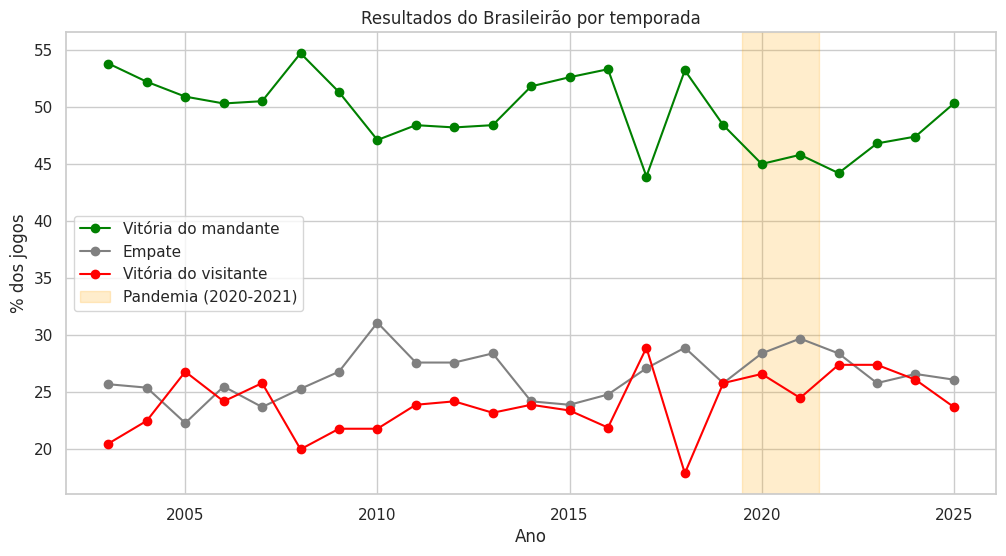

In [331]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

plt.plot(tabela.index, tabela["Mandante"], marker="o", label="Vitória do mandante", color="green")
plt.plot(tabela.index, tabela["Empate"], marker="o", label="Empate", color="gray")
plt.plot(tabela.index, tabela["Visitante"], marker="o", label="Vitória do visitante", color="red")

# Destaca o período da pandemia
plt.axvspan(2019.5, 2021.5, color="orange", alpha=0.2, label="Pandemia (2020-2021)")

plt.title("Resultados do Brasileirão por temporada")
plt.xlabel("Ano")
plt.ylabel("% dos jogos")
plt.legend()
plt.savefig("fig1_resultados_por_temporada.png", dpi=150, bbox_inches="tight")
plt.show()

In [313]:
print("Média geral (2003 até hoje):")
print((df["resultado"].value_counts(normalize=True) * 100).round(1))

print("\nMédia de gols do mandante:", round(df["mandante_Placar"].mean(), 2))
print("Média de gols do visitante:", round(df["visitante_Placar"].mean(), 2))

Média geral (2003 até hoje):
resultado
Mandante     49.6
Empate       26.4
Visitante    23.9
Name: proportion, dtype: float64

Média de gols do mandante: 1.54
Média de gols do visitante: 1.03


In [314]:
d16 = df[df["ano"] == 2016]
jogos_2016 = pd.concat([d16["mandante"], d16["visitante"]]).value_counts()
jogos_2016.tail(3)

,count
Gremio,38
Atletico-MG,37
Chapecoense,37


In [315]:
def periodo(ano):
    if ano <= 2009:
        return "2003-2009"
    elif ano <= 2019:
        return "2010-2019"
    elif ano <= 2021:
        return "2020-2021 (pandemia)"
    else:
        return "2022-2025"

df["periodo"] = df["ano"].apply(periodo)

por_periodo = pd.crosstab(df["periodo"], df["resultado"], normalize="index") * 100
por_periodo.round(1)

resultado,Empate,Mandante,Visitante
periodo,,,
2003-2009,25.0,52.0,23.0
2010-2019,27.0,49.5,23.5
2020-2021 (pandemia),29.1,45.4,25.5
2022-2025,26.7,47.2,26.1


In [316]:
n = df.groupby("periodo").size()
p = por_periodo["Mandante"] / 100
margem = 1.96 * np.sqrt(p * (1 - p) / n) * 100

pd.DataFrame({
    "jogos": n,
    "% mandante": (p * 100).round(1),
    "margem de erro (±)": margem.round(1),
})

,jogos,% mandante,margem de erro (±)
periodo,,,
2003-2009,3086,52.0,1.8
2010-2019,3799,49.5,1.6
2020-2021 (pandemia),760,45.4,3.5
2022-2025,1520,47.2,2.5


In [317]:
casa = pd.DataFrame({
    "ano": df["ano"],
    "time": df["mandante"],
    "local": "Casa",
    "gols_pro": df["mandante_Placar"],
    "gols_contra": df["visitante_Placar"],
})

fora = pd.DataFrame({
    "ano": df["ano"],
    "time": df["visitante"],
    "local": "Fora",
    "gols_pro": df["visitante_Placar"],
    "gols_contra": df["mandante_Placar"],
})

jogos = pd.concat([casa, fora], ignore_index=True)

jogos["pontos"] = np.select(
    [jogos["gols_pro"] > jogos["gols_contra"], jogos["gols_pro"] == jogos["gols_contra"]],
    [3, 1],
    default=0,
)
jogos["vitoria"] = (jogos["gols_pro"] > jogos["gols_contra"]).astype(int)
jogos["saldo"] = jogos["gols_pro"] - jogos["gols_contra"]

In [318]:
classificacao = (
    jogos.groupby(["ano", "time"])
    .agg(
        jogos=("pontos", "size"),
        pontos=("pontos", "sum"),
        vitorias=("vitoria", "sum"),
        gols_pro=("gols_pro", "sum"),
        gols_contra=("gols_contra", "sum"),
        saldo=("saldo", "sum"),
    )
    .reset_index()
)

# Critérios de desempate: pontos, vitórias, saldo de gols, gols marcados
classificacao = classificacao.sort_values(
    ["ano", "pontos", "vitorias", "saldo", "gols_pro"],
    ascending=[True, False, False, False, False],
)
classificacao["posicao"] = classificacao.groupby("ano").cumcount() + 1

In [319]:
campeoes = classificacao[classificacao["posicao"] == 1]
campeoes[["ano", "time", "jogos", "pontos", "vitorias", "gols_pro", "gols_contra", "saldo"]]

,ano,time,jogos,pontos,vitorias,gols_pro,gols_contra,saldo
6,2003,Cruzeiro,46,100,31,102,47,55
43,2004,Santos,46,89,27,103,58,45
52,2005,Corinthians,42,81,24,87,59,28
88,2006,Sao Paulo,38,78,22,66,32,34
107,2007,Sao Paulo,38,77,23,55,19,36
126,2008,Sao Paulo,38,75,21,66,36,30
138,2009,Flamengo,38,67,19,58,44,14
160,2010,Fluminense,38,71,20,62,36,26
178,2011,Corinthians,38,71,21,53,36,17
199,2012,Fluminense,38,77,22,61,33,28


In [320]:
df["mandante"].nunique()

45

In [321]:
sorted(df["mandante"].unique())

['America-MG',
 'America-RN',
 'Athletico-PR',
 'Atletico-GO',
 'Atletico-MG',
 'Avai',
 'Bahia',
 'Barueri',
 'Botafogo-RJ',
 'Bragantino',
 'Brasiliense',
 'CSA',
 'Ceara',
 'Chapecoense',
 'Corinthians',
 'Coritiba',
 'Criciuma',
 'Cruzeiro',
 'Cuiaba',
 'Figueirense',
 'Flamengo',
 'Fluminense',
 'Fortaleza',
 'Goias',
 'Gremio',
 'Guarani',
 'Internacional',
 'Ipatinga',
 'Joinville',
 'Juventude',
 'Mirassol',
 'Nautico',
 'Palmeiras',
 'Parana',
 'Paysandu',
 'Ponte Preta',
 'Portuguesa',
 'Santa Cruz',
 'Santo Andre',
 'Santos',
 'Sao Caetano',
 'Sao Paulo',
 'Sport',
 'Vasco',
 'Vitoria']

In [322]:
classificacao["aproveitamento"] = (
    classificacao["pontos"] / (classificacao["jogos"] * 3) * 100
).round(1)

campeoes = classificacao[classificacao["posicao"] == 1]
campeoes[["ano", "time", "pontos", "aproveitamento"]]

,ano,time,pontos,aproveitamento
6,2003,Cruzeiro,100,72.5
43,2004,Santos,89,64.5
52,2005,Corinthians,81,64.3
88,2006,Sao Paulo,78,68.4
107,2007,Sao Paulo,77,67.5
126,2008,Sao Paulo,75,65.8
138,2009,Flamengo,67,58.8
160,2010,Fluminense,71,62.3
178,2011,Corinthians,71,62.3
199,2012,Fluminense,77,67.5


In [323]:
print(campeoes["time"].value_counts())
print("\nAproveitamento médio dos campeões:", campeoes["aproveitamento"].mean().round(1), "%")
print("Aproveitamento mínimo:", campeoes["aproveitamento"].min(), "%")
print("Aproveitamento máximo:", campeoes["aproveitamento"].max(), "%")

time
Corinthians    4
Palmeiras      4
Flamengo       4
Cruzeiro       3
Sao Paulo      3
Fluminense     2
Santos         1
Atletico-MG    1
Botafogo-RJ    1
Name: count, dtype: int64

Aproveitamento médio dos campeões: 67.5 %
Aproveitamento mínimo: 58.8 %
Aproveitamento máximo: 78.9 %


In [324]:
aprov = (
    jogos.groupby(["ano", "time", "local"])["pontos"].mean().unstack() / 3 * 100
).reset_index()
aprov.columns.name = None
aprov = aprov.rename(columns={"Casa": "aprov_casa", "Fora": "aprov_fora"})
aprov["dif_casa_fora"] = aprov["aprov_casa"] - aprov["aprov_fora"]

base = classificacao.merge(aprov, on=["ano", "time"])
base["grupo"] = np.where(base["posicao"] == 1, "Campeão", "Demais")

base.groupby("grupo")[["aprov_casa", "aprov_fora", "dif_casa_fora"]].mean().round(1)

,aprov_casa,aprov_fora,dif_casa_fora
grupo,,,
Campeão,78.0,56.9,21.1
Demais,57.4,31.6,25.8


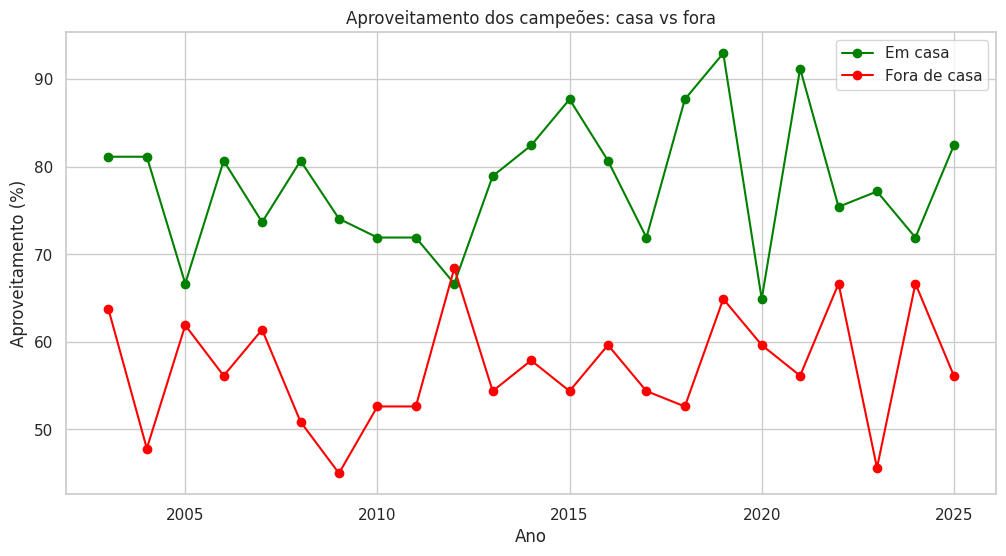

In [325]:
camp = base[base["grupo"] == "Campeão"].sort_values("ano")

plt.figure(figsize=(12, 6))
plt.plot(camp["ano"], camp["aprov_casa"], marker="o", color="green", label="Em casa")
plt.plot(camp["ano"], camp["aprov_fora"], marker="o", color="red", label="Fora de casa")
plt.title("Aproveitamento dos campeões: casa vs fora")
plt.xlabel("Ano")
plt.ylabel("Aproveitamento (%)")
plt.legend()
plt.savefig("fig2_campeoes_casa_fora.png", dpi=150, bbox_inches="tight")
plt.show()

In [326]:
base["periodo"] = base["ano"].apply(periodo)

base.groupby("periodo")[["aprov_casa", "aprov_fora", "dif_casa_fora"]].mean().round(1)

,aprov_casa,aprov_fora,dif_casa_fora
periodo,,,
2003-2009,60.3,31.4,29.0
2010-2019,58.5,32.5,26.0
2020-2021 (pandemia),55.1,35.2,19.9
2022-2025,56.1,35.0,21.1


In [327]:
base[base["grupo"] == "Campeão"].groupby("periodo")[["aprov_casa", "aprov_fora", "dif_casa_fora"]].mean().round(1)

,aprov_casa,aprov_fora,dif_casa_fora
periodo,,,
2003-2009,76.9,55.3,21.6
2010-2019,79.3,57.2,22.1
2020-2021 (pandemia),78.1,57.9,20.2
2022-2025,76.8,58.8,18.0


In [328]:
b38 = base[base["ano"] >= 2006]

b38[["posicao", "aprov_casa", "aprov_fora"]].corr()["posicao"].round(2)

,posicao
posicao,1.00
aprov_casa,-0.82
aprov_fora,-0.79


In [329]:
top = b38[b38["posicao"] <= 6]
top.groupby("posicao")[["aprov_casa", "aprov_fora"]].mean().round(1)

,aprov_casa,aprov_fora
posicao,,
1,78.3,56.8
2,72.6,49.6
3,73.6,44.8
4,69.1,43.2
5,66.8,40.5
6,66.1,36.8


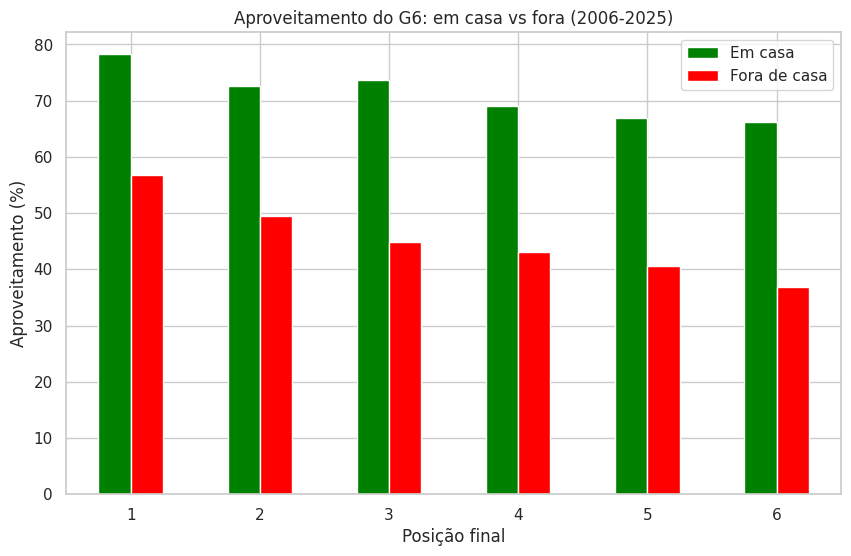

In [330]:
g6 = top.groupby("posicao")[["aprov_casa", "aprov_fora"]].mean()

g6.plot(kind="bar", figsize=(10, 6), color=["green", "red"])
plt.title("Aproveitamento do G6: em casa vs fora (2006-2025)")
plt.xlabel("Posição final")
plt.ylabel("Aproveitamento (%)")
plt.xticks(rotation=0)
plt.legend(["Em casa", "Fora de casa"])
plt.savefig("fig3_g6_casa_fora.png", dpi=150, bbox_inches="tight")
plt.show()